# Mirror alignment: stability metrics and simulations

**AST430 progress, Irmak Aytekin**

The metrology laser bounces off the mirrors and makes **fringes** (bright and dark stripes) on a camera.
The stripes tell us where the mirror is, how tilted it is, and whether it is shaking.

This notebook turns "is the mirror stable?" into **numbers with error bars**, and simulates the main steps:

| Part | Question | Output |
|---|---|---|
| 1 | What does the camera see? | Fake fringe images |
| 2 | How much does the mirror wobble? | RMS ± error, and why the time window matters |
| 3 | How sharp are the fringes? | Modulation efficiency ± error from a fit |
| 4 | How does shaking wash out the fringes? | Simulation vs formula |
| 5 | How does tilt wash out the fringes? | Simulation vs formula |
| 6 | How tilted is the mirror? | Tilt from fringe spacing |
| 7 | Do the piezos have enough room? | Safe range with the real piezo numbers |
| 8 | Can the piezos settle after an actuator move? | Settle-step simulation |
| 9 | Is there a tilt bias after each move? | How we would detect it |

**All data here is simulated.** Next step: run the same functions on real frames from the visible laser.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import j1          # Bessel function, used in Part 5

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(1)        # fixed seed so the results repeat

# ---- Numbers from Servo and from the Oct 19 meeting ----
WAVELENGTH_NM   = 1550.0   # metrology laser (Servo config.py). Change for the visible laser.
CAMERA_FPS      = 1000     # metrology camera rate (meeting)
PIEZO_TRAVEL_UM = 12.0     # full piezo travel (meeting)
PIEZO_START_UM  = 6.0      # piezos start halfway (meeting)
ACTUATOR_ERR_UM = 0.2      # actuator lands within 0.2 um of the target (meeting)
MOD_EFF_NOW     = 0.86     # current modulation efficiency (meeting)

## Part 1: What the camera sees

Two halves of the laser beam travel to the two mirrors and come back together.
Where the peaks of the two waves line up, the camera sees **bright**; where a peak meets a dip, **dark**.

- **Tilt** makes the stripes appear across the image: more tilt means stripes packed closer together.
- **Piston** (mirror moving forward/back) slides the stripes sideways.
- **Shaking during one camera exposure** smears the stripes, so they look washed out.

The function below makes a fake camera image so we can test the code without the lab.

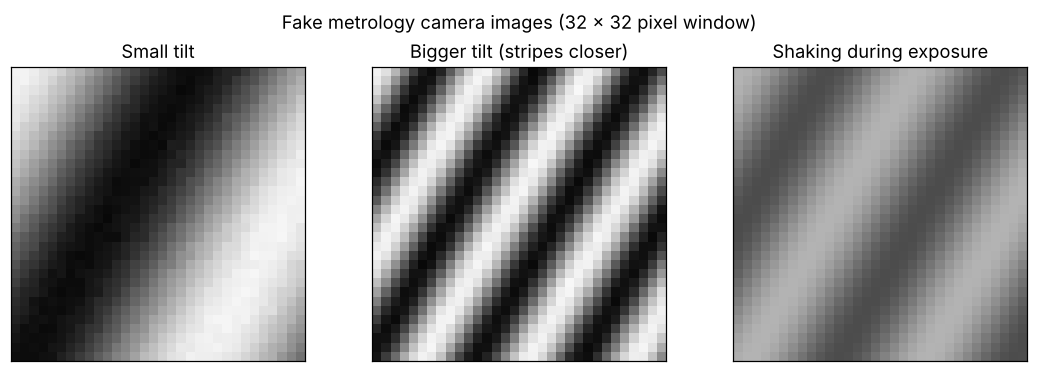

In [2]:
def make_fringe_image(roi=32, fringe_freq=0.06, angle_deg=30, opd_nm=0.0,
                      contrast=0.9, noise=0.02):
    '''Fake camera image of straight fringes.

    fringe_freq : stripes per pixel (more tilt -> bigger number)
    angle_deg   : direction of the stripes
    opd_nm      : mirror piston, shifts the stripes sideways
    contrast    : how sharp the stripes are (1 = perfect)
    noise       : camera noise
    '''
    y, x = np.mgrid[0:roi, 0:roi]                       # pixel coordinates
    k = 2 * np.pi * fringe_freq                         # stripes per pixel -> radians per pixel
    a = np.radians(angle_deg)
    phase = 2 * np.pi * opd_nm / WAVELENGTH_NM          # piston -> phase shift
    img = 1 + contrast * np.cos(k * (np.cos(a) * x + np.sin(a) * y) + phase)
    return img + noise * rng.standard_normal(img.shape)


def shaken_exposure(jitter_rms_nm, n_sub=200, **kw):
    '''One camera exposure while the mirror shakes: average many shifted images.'''
    shifts = jitter_rms_nm * rng.standard_normal(n_sub)
    return np.mean([make_fringe_image(opd_nm=s, noise=0, **kw) for s in shifts], axis=0)


fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
examples = [("Small tilt", make_fringe_image(fringe_freq=0.03)),
            ("Bigger tilt (stripes closer)", make_fringe_image(fringe_freq=0.10)),
            ("Shaking during exposure", shaken_exposure(300, fringe_freq=0.06))]
for ax, (title, img) in zip(axes, examples):
    ax.imshow(img, cmap="gray", vmin=0, vmax=2)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Fake metrology camera images (32 x 32 pixel window)")
plt.tight_layout(); plt.show()

## Part 2: How much does the mirror wobble? (RMS)

We record the mirror position (OPD) 1000 times a second. Even when the mirror should be still, it jiggles.
**RMS is the typical size of that jiggle.**

**Error bar:** cut the time window into 10 blocks and measure the RMS of each.
If the blocks agree, the error is small. This is more honest than the textbook formula,
because vibration makes neighbouring samples similar (they are not independent).

The fake signal below mixes three things: a slow drift (0.5 Hz), a 50 Hz vibration, and random noise.

RMS over the full 10 s exposure: 15.1 +- 0.1 nm


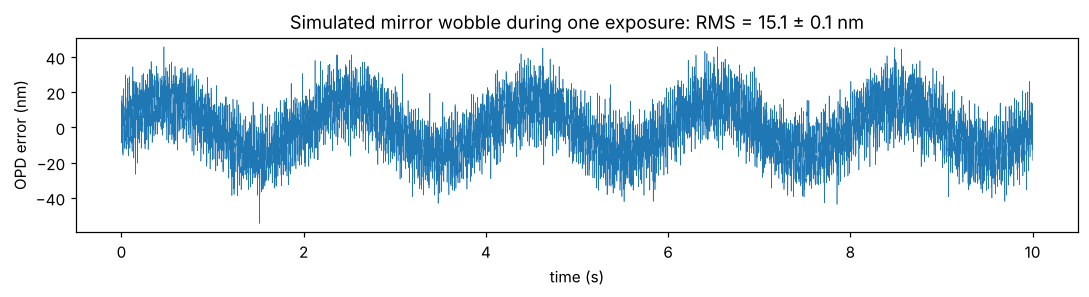

In [3]:
def rms_with_error(signal, fs_hz, window_s, n_blocks=10):
    '''RMS of the last `window_s` seconds of `signal`, with a block-method error bar.'''
    n = int(window_s * fs_hz)                    # samples in the window
    x = np.asarray(signal[-n:], dtype=float)
    rms = x.std()                                # typical size of the wobble
    blocks = np.array_split(x, n_blocks)         # 10 equal pieces
    block_rms = np.array([b.std() for b in blocks])
    err = block_rms.std(ddof=1) / np.sqrt(n_blocks)
    return rms, err


# 10 seconds of fake mirror position, sampled at the camera rate
t = np.arange(0, 10, 1 / CAMERA_FPS)
opd = (15 * np.sin(2 * np.pi * 0.5 * t)          # slow drift
       + 10 * np.sin(2 * np.pi * 50 * t)          # 50 Hz vibration
       + 8 * rng.standard_normal(t.size))         # random noise   (all in nm, made up)

rms, err = rms_with_error(opd, CAMERA_FPS, window_s=10)
print(f"RMS over the full 10 s exposure: {rms:.1f} +- {err:.1f} nm")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(t, opd, lw=0.4, color="tab:blue")
ax.set_xlabel("time (s)"); ax.set_ylabel("OPD error (nm)")
ax.set_title(f"Simulated mirror wobble during one exposure: RMS = {rms:.1f} ± {err:.1f} nm")
plt.tight_layout(); plt.show()

### Why the time window matters

If we only watch for a short time, we miss the slow drift and the mirror *looks* calmer than it is.
The RMS only settles once the window covers a few cycles of the slowest wobble.
That's why the RMS for the science case should use the **full exposure (5 to 10 s)**.

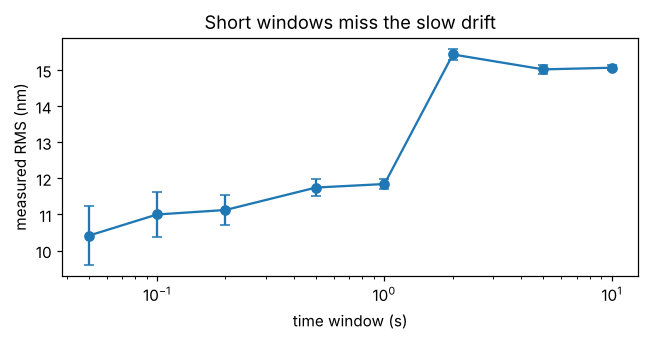

In [4]:
windows = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10])   # seconds
results = np.array([rms_with_error(opd, CAMERA_FPS, w) for w in windows])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(windows, results[:, 0], yerr=results[:, 1], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("time window (s)"); ax.set_ylabel("measured RMS (nm)")
ax.set_title("Short windows miss the slow drift")
plt.tight_layout(); plt.show()

## Part 3: How sharp are the fringes? (modulation efficiency)

We fit a perfect stripe pattern to the image:

$$I(x,y) = \text{mean} + \text{amp}\cdot\cos(k_x x + k_y y + \text{phase})$$

$$\text{Modulation efficiency} = \frac{\text{amp}}{\text{mean}} \quad (1 = \text{perfect stripes},\ 0 = \text{no stripes})$$

The fit also tells us how uncertain each number is, which gives the error bar.
The FFT gives the fit a good starting guess (it finds the strongest stripe pattern in the image).

Modulation efficiency: 0.861 +- 0.003   (true value 0.86)
Stripe frequency     : 0.0600 +- 0.0000 stripes/pixel (true 0.06)


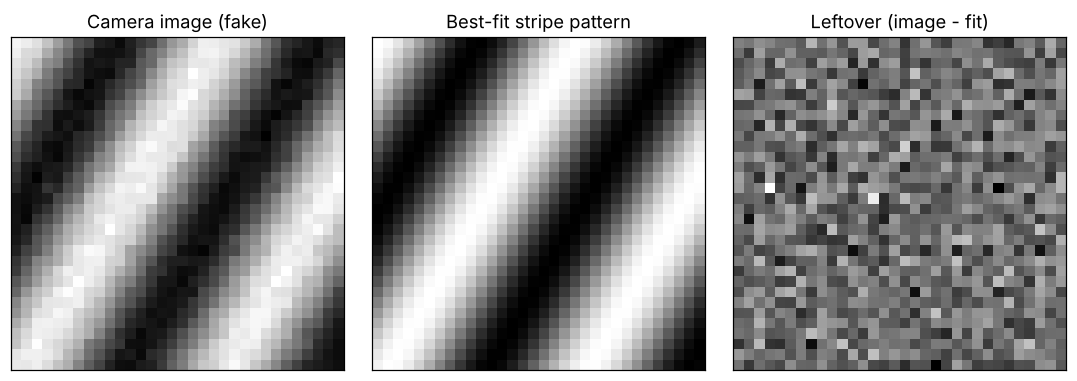

In [5]:
def _fringe_model(xy, mean, amp, kx, ky, phase):
    x, y = xy
    return mean + amp * np.cos(kx * x + ky * y + phase)


def fit_fringes(image):
    '''Fit straight fringes; return modulation efficiency and stripe frequency, with errors.'''
    img = np.asarray(image, dtype=float)
    ny, nx = img.shape
    y, x = np.mgrid[0:ny, 0:nx]

    # Starting guess from the brightest peak of the 2D FFT
    F = np.fft.fft2(img - img.mean()); F[0, 0] = 0
    iy, ix = np.unravel_index(np.argmax(np.abs(F)), F.shape)
    p0 = [img.mean(), (img.max() - img.min()) / 2,
          2 * np.pi * np.fft.fftfreq(nx)[ix], 2 * np.pi * np.fft.fftfreq(ny)[iy], 0.0]

    popt, pcov = curve_fit(_fringe_model, (x.ravel(), y.ravel()), img.ravel(), p0=p0)
    mean, amp, kx, ky, _ = popt
    perr = np.sqrt(np.diag(pcov))                 # 1-sigma errors from the fit
    amp = abs(amp)

    me = amp / mean
    me_err = me * np.hypot(perr[1] / amp, perr[0] / mean)
    k = np.hypot(kx, ky)
    k_err = np.hypot(kx * perr[2], ky * perr[3]) / k
    return dict(mod_eff=me, mod_eff_err=me_err,
                fringe_freq=k / (2 * np.pi), fringe_freq_err=k_err / (2 * np.pi),
                fit=_fringe_model((x, y), *popt))


img = make_fringe_image(contrast=MOD_EFF_NOW, noise=0.05)    # fake image with 86% contrast
res = fit_fringes(img)
print(f"Modulation efficiency: {res['mod_eff']:.3f} +- {res['mod_eff_err']:.3f}   (true value {MOD_EFF_NOW})")
print(f"Stripe frequency     : {res['fringe_freq']:.4f} +- {res['fringe_freq_err']:.4f} stripes/pixel (true 0.06)")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (title, im) in zip(axes, [("Camera image (fake)", img),
                                   ("Best-fit stripe pattern", res["fit"]),
                                   ("Leftover (image - fit)", img - res["fit"])]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Over many frames, the **average** gives the best value, and the **frame-to-frame scatter**
is itself a stability measure: a steady mirror gives the same answer every frame.

In [6]:
def frames_summary(frames):
    '''Fit every frame: mean +- error of the mean, plus frame-to-frame scatter.'''
    fits = [fit_fringes(f) for f in frames]
    out = {}
    for key in ("mod_eff", "fringe_freq"):
        v = np.array([f[key] for f in fits])
        out[key] = v.mean()
        out[key + "_err"] = v.std(ddof=1) / np.sqrt(len(v))
        out[key + "_scatter"] = v.std(ddof=1)
    return out


frames = [make_fringe_image(contrast=MOD_EFF_NOW, opd_nm=o, noise=0.05)
          for o in 30 * rng.standard_normal(100)]               # 100 frames, mirror wobbling
s = frames_summary(frames)
print(f"Modulation efficiency over 100 frames: {s['mod_eff']:.4f} +- {s['mod_eff_err']:.4f} "
      f"(scatter {s['mod_eff_scatter']:.4f})")

Modulation efficiency over 100 frames: 0.8601 +- 0.0003 (scatter 0.0027)


## Part 4: Shaking washes out the fringes

If the mirror shakes **during** one exposure, the stripes slide back and forth and smear.
For random shaking with RMS $\sigma$, the contrast left is:

$$\text{ME}_\text{vib} = \exp\left[-\tfrac{1}{2}\left(\frac{2\pi\,\sigma_\text{OPD}}{\lambda}\right)^2\right]$$

Below: simulate shaken exposures, measure the contrast with the fit, and compare with the formula.
The second curve shows that **the same shaking hurts shorter wavelengths more**
(650 nm is just an example of visible light).

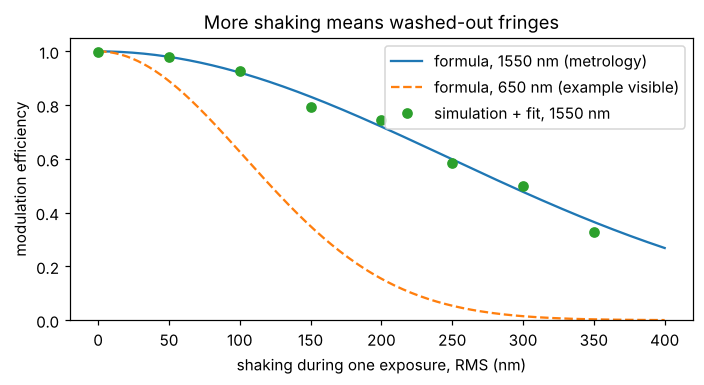

In [7]:
def predicted_mod_eff_vibration(opd_rms_nm, wavelength_nm=WAVELENGTH_NM):
    return np.exp(-0.5 * (2 * np.pi * opd_rms_nm / wavelength_nm) ** 2)


jitters = np.array([0, 50, 100, 150, 200, 250, 300, 350])        # nm RMS
measured = [fit_fringes(shaken_exposure(j, contrast=1.0) + 0.01 * rng.standard_normal((32, 32)))["mod_eff"]
            for j in jitters]

curve = np.linspace(0, 400, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curve, predicted_mod_eff_vibration(curve), label="formula, 1550 nm (metrology)")
ax.plot(curve, predicted_mod_eff_vibration(curve, 650), "--", label="formula, 650 nm (example visible)")
ax.plot(jitters, measured, "o", label="simulation + fit, 1550 nm")
ax.set_xlabel("shaking during one exposure, RMS (nm)"); ax.set_ylabel("modulation efficiency")
ax.set_title("More shaking means washed-out fringes"); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

In [ ]:
add a line for 350nm - smallest wavelength if the wavelength is shorter it should be better for correcting small variations. 
actively correcting for vibration in the system, at a rate for 1000 images for second hundreds of nm/s --> correct or you lose the the modeff
have a simulation on the rate of correcting for the 1000 images of the system

## Part 5: Tilt washes out the fringes (for a detector that sums the whole beam)

On the metrology camera, tilt makes stripes *across* the image.
But a detector pixel that **adds up the whole beam** (like the science detector) sees all those
stripes at once, and they cancel each other out. For a round beam of radius $R$ and mirror tilt $\alpha$:

$$\text{ME}_\text{tilt} = \left|\frac{2J_1(u)}{u}\right|, \qquad u = \frac{4\pi\,\alpha R}{\lambda}$$

(The 4π instead of 2π is because reflection doubles the tilt.)
Below: a brute-force simulation over a round beam, compared with the formula.
**The beam radius is an example value: change it to ours.**

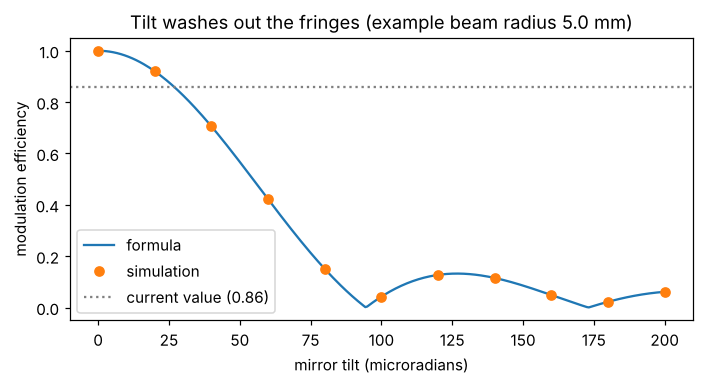

In [8]:
BEAM_RADIUS_MM = 5.0        # EXAMPLE value, to replace with the real beam size

def predicted_mod_eff_tilt(tilt_urad, radius_mm=BEAM_RADIUS_MM, wavelength_nm=WAVELENGTH_NM):
    u = 4 * np.pi * (tilt_urad * 1e-6) * (radius_mm * 1e-3) / (wavelength_nm * 1e-9)
    u = np.where(u == 0, 1e-12, u)
    return np.abs(2 * j1(u) / u)

def simulated_mod_eff_tilt(tilt_urad, radius_mm=BEAM_RADIUS_MM, n=301):
    '''Average the light over a round beam with a tilted wavefront.'''
    x = np.linspace(-1, 1, n) * radius_mm * 1e-3
    X, Y = np.meshgrid(x, x)
    inside = X**2 + Y**2 <= (radius_mm * 1e-3) ** 2
    phase = 2 * np.pi * (2 * tilt_urad * 1e-6 * X) / (WAVELENGTH_NM * 1e-9)
    return np.abs(np.exp(1j * phase[inside]).mean())

tilts = np.linspace(0, 200, 300)
sim_tilts = np.arange(0, 201, 20)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(tilts, predicted_mod_eff_tilt(tilts), label="formula")
ax.plot(sim_tilts, [simulated_mod_eff_tilt(a) for a in sim_tilts], "o", label="simulation")
ax.axhline(MOD_EFF_NOW, color="gray", ls=":", label=f"current value ({MOD_EFF_NOW})")
ax.set_xlabel("mirror tilt (microradians)"); ax.set_ylabel("modulation efficiency")
ax.set_title(f"Tilt washes out the fringes (example beam radius {BEAM_RADIUS_MM} mm)")
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
relatively larger - 1 inch

## Part 6: How tilted is the mirror?

More tilt means stripes packed closer together. Reflection doubles the angle, so one stripe
across a distance $d$ on the mirror means tilt $= \lambda / (2d)$.

To go from "stripes per pixel" to a real angle we need the **pixel scale** (how much mirror one pixel covers).
That number is still to be measured, so the value below is a **placeholder**.

Note: on the metrology camera some stripes are there on purpose (in Servo's setup the laser comes in at an angle),
so the useful number is how much the tilt **changes** from frame to frame. A steady mirror gives a small scatter.

In [9]:
PIXEL_SCALE_UM = 30.0       # PLACEHOLDER: size of one camera pixel on the mirror, to be measured

def tilt_from_fringes(fringe_freq, fringe_freq_err, pixel_scale_um=PIXEL_SCALE_UM,
                      wavelength_nm=WAVELENGTH_NM):
    period_um = pixel_scale_um / fringe_freq                  # stripe spacing on the mirror
    tilt_urad = wavelength_nm * 1e-3 / (2 * period_um) * 1e6  # the 2: reflection doubles the angle
    return tilt_urad, tilt_urad * fringe_freq_err / fringe_freq

tilt, tilt_err = tilt_from_fringes(s["fringe_freq"], s["fringe_freq_err"])
tilt_scatter, _ = tilt_from_fringes(s["fringe_freq_scatter"], 0)   # same conversion for the scatter
print(f"Tilt (includes the deliberate stripes): {tilt:.1f} +- {tilt_err:.2f} microradians")
print(f"Tilt stability, frame-to-frame scatter : {tilt_scatter:.3f} microradians")
print("(both use the placeholder pixel scale)")

Tilt (includes the deliberate stripes): 1550.3 +- 0.10 microradians
Tilt stability, frame-to-frame scatter : 1.016 microradians
(both use the placeholder pixel scale)


In [ ]:
we might not be able to feed the perfect number but we might have to compute it after moving the piezo actively
use 15m icrons for camera pixel scale
to need 6 microns (probably gonn NEED MUCH UNDER THATH LIKE half a fringe) you have to be very misaligned
track from 0 opd max flux and move and decide on the right fringes and keep tracking the position

## Part 7: Do the piezos have enough room?

From the meeting: the piezos travel **12 µm** and start halfway (**6 µm**), so there are 6 µm of room each way.
The actuator lands within **0.2 µm**, so the settle step only needs a tiny part of that range.
we expect we'll never use more than about **10%** of the travel.

 keep a margin at each end (here 20%) so the piezos never hit their limits.

Safe range: 2.4 to 9.6 um  (start at 6.0 um)
Settle gap (0.2 um) uses 3% of the room on one side


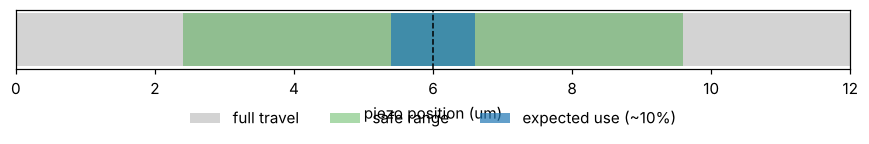

In [10]:
def piezo_safe_range(travel_um=PIEZO_TRAVEL_UM, margin_frac=0.2):
    lo, hi = margin_frac * travel_um, (1 - margin_frac) * travel_um
    return dict(lo=lo, hi=hi)

def piezo_ok(position_um, safe):
    '''If outside the safe range, the actuator should take over and the piezo re-centres.'''
    return safe["lo"] <= position_um <= safe["hi"]

safe = piezo_safe_range()
print(f"Safe range: {safe['lo']:.1f} to {safe['hi']:.1f} um  (start at {PIEZO_START_UM} um)")
print(f"Settle gap ({ACTUATOR_ERR_UM} um) uses {ACTUATOR_ERR_UM / (PIEZO_TRAVEL_UM/2):.0%} of the room on one side")

fig, ax = plt.subplots(figsize=(8, 1.8))
ax.barh(0, PIEZO_TRAVEL_UM, color="lightgray", label="full travel")
ax.barh(0, safe["hi"] - safe["lo"], left=safe["lo"], color="tab:green", alpha=0.4, label="safe range")
ax.barh(0, 0.1 * PIEZO_TRAVEL_UM, left=PIEZO_START_UM - 0.05 * PIEZO_TRAVEL_UM,
        color="tab:blue", alpha=0.7, label="expected use (~10%)")
ax.axvline(PIEZO_START_UM, color="k", ls="--", lw=1)
ax.set_yticks([]); ax.set_xlabel("piezo position (um)"); ax.set_xlim(0, PIEZO_TRAVEL_UM)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

## Part 8: Simulating the settle step

After each actuator move, the mirror is up to 0.2 µm away from its target.
The piezos close that gap with a simple feedback loop, 1000 times a second:

```
error = target - measured position
piezo command += gain * error
```

The model includes small vibration, camera noise, and a piezo that doesn't react instantly.
A bigger gain settles faster, but too big starts to overshoot. **All numbers are made up for illustration.**

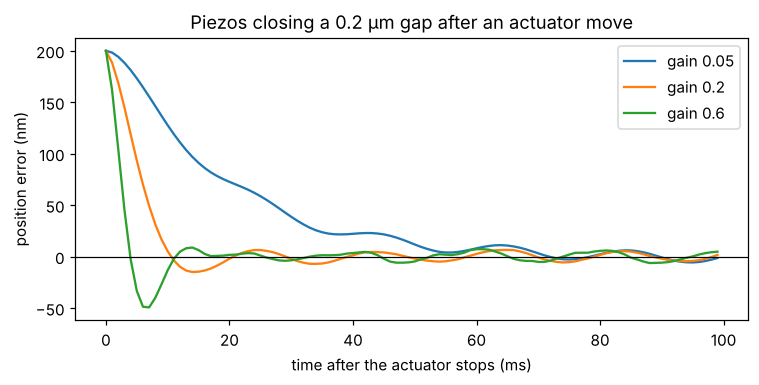

In [11]:
def simulate_settle(start_error_nm, gain, t_end=0.1, fs=CAMERA_FPS,
                    piezo_lag_s=0.003, vib_nm=5, meas_noise_nm=3):
    '''Return time and position error (nm) while the piezo closes the gap.'''
    n = int(t_end * fs); dt = 1 / fs
    command = 0.0                 # what we tell the piezo
    piezo = 0.0                   # where the piezo actually is (it lags behind)
    t = np.arange(n) * dt
    error = np.empty(n)
    for i in range(n):
        true_err = start_error_nm - piezo + vib_nm * np.sin(2 * np.pi * 50 * t[i])
        measured = true_err + meas_noise_nm * rng.standard_normal()   # what the camera sees
        command += gain * measured                                    # feedback: push toward target
        piezo += (command - piezo) * dt / piezo_lag_s                 # piezo catches up gradually
        error[i] = true_err
    return t, error

fig, ax = plt.subplots(figsize=(7, 3.6))
for gain in [0.05, 0.2, 0.6]:
    t_s, e = simulate_settle(200, gain)          # start 200 nm (0.2 um) away
    ax.plot(t_s * 1000, e, label=f"gain {gain}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("time after the actuator stops (ms)"); ax.set_ylabel("position error (nm)")
ax.set_title("Piezos closing a 0.2 µm gap after an actuator move"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
gain is likely to be bigger - larger flux also for sitelle ~3.0

### A full scan: 50 steps

Each step the actuator lands somewhere within ±0.2 µm, and the piezo takes up the difference.
Because the errors are random, the piezo wanders around its centre but stays well inside the safe range.
If it ever left the safe range, the code would let the actuator take over (offload) and re-centre the piezo.

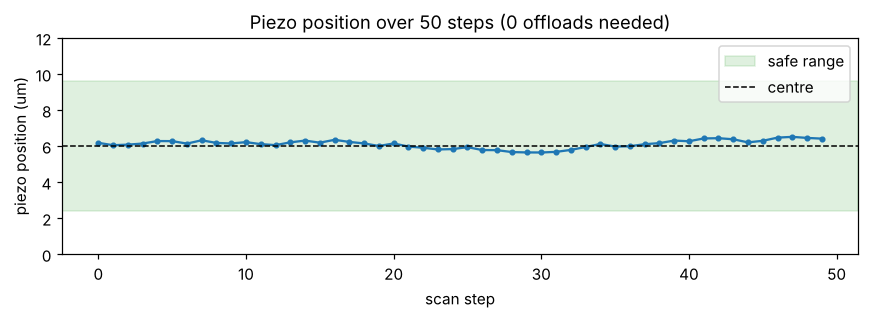

In [12]:
piezo_pos = PIEZO_START_UM
history, offloads = [], 0
for step in range(50):
    landing_error = rng.uniform(-ACTUATOR_ERR_UM, ACTUATOR_ERR_UM)   # where the actuator really stopped
    piezo_pos += landing_error                                        # piezo makes up the difference
    if not piezo_ok(piezo_pos, safe):                                 # too close to a limit?
        piezo_pos = PIEZO_START_UM                                    # offload to actuator, re-centre
        offloads += 1
    history.append(piezo_pos)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history, "o-", ms=3)
ax.axhspan(safe["lo"], safe["hi"], color="tab:green", alpha=0.15, label="safe range")
ax.axhline(PIEZO_START_UM, color="k", ls="--", lw=1, label="centre")
ax.set_xlabel("scan step"); ax.set_ylabel("piezo position (um)"); ax.set_ylim(0, PIEZO_TRAVEL_UM)
ax.set_title(f"Piezo position over 50 steps ({offloads} offloads needed)"); ax.legend()
plt.tight_layout(); plt.show()

## Part 9: Is there a tilt bias after each actuator move?

Question from the meeting: when the actuator moves step after step, does it tilt the mirror
**the same way every time**? If so, the code could correct it in advance instead of waiting to see it.

How to check: record the tilt after each step, then see whether the average is clearly different from zero.
Below is **fake data with a small bias built in**, to show the method. With real data from the actuator,
we run exactly the same test.

Average is 3.0 error bars away from zero: a real bias


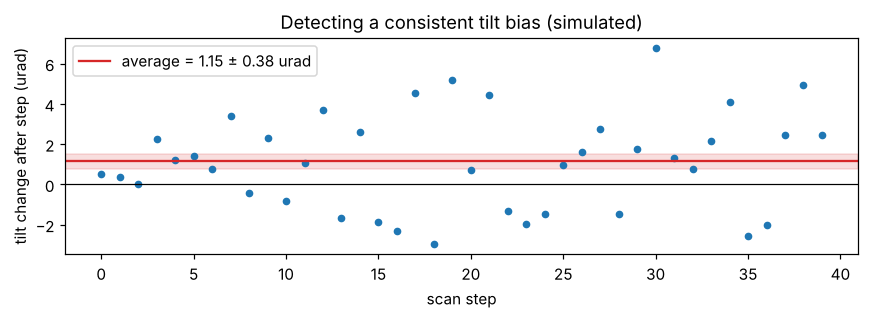

In [13]:
n_steps = 40
true_bias = 1.5                                      # urad per step, FAKE
tilt_after_step = true_bias + 2.0 * rng.standard_normal(n_steps)   # bias + random scatter

mean = tilt_after_step.mean()
err = tilt_after_step.std(ddof=1) / np.sqrt(n_steps)  # error on the mean
significance = mean / err

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tilt_after_step, "o", ms=4)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(mean, color="tab:red", label=f"average = {mean:.2f} ± {err:.2f} urad")
ax.axhspan(mean - err, mean + err, color="tab:red", alpha=0.15)
ax.set_xlabel("scan step"); ax.set_ylabel("tilt change after step (urad)")
ax.set_title("Detecting a consistent tilt bias (simulated)"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Average is {significance:.1f} error bars away from zero:",
      "a real bias" if abs(significance) > 3 else "no clear bias")

In [ ]:
any modifications because of rooftop mirrors?
if their code was built for the metrology camera?
if we can use zilingc code for some simulatiosn

## Summary

- **Stability as numbers:** RMS, modulation efficiency and tilt, each with an error bar.
- **Fit works:** on simulated frames it recovers the true contrast and stripe spacing.
- **What washes out fringes:** shaking (worse at shorter wavelengths) and tilt, checked against formulas.
- **Piezo room is not a problem:** 12 µm travel; settling a 0.2 µm gap uses about 3% of one side.
- **Settle step and tilt-bias test** are simulated and ready to try on the bench.

**Next steps**
1. Record real frames with the visible laser and run Parts 2, 3 and 6 on them.
2. Measure the camera pixel scale and the beam size (to replace the placeholders in Parts 5 and 6).
3. Ask Ziling how jitter affects modulation efficiency, and compare with Part 4.
4. Run the tilt-bias test (Part 9) once the actuator arrives.